# **Analysis of Sentiment in News Articles Regarding Developments in NLP and RNN Architectures Using Deep Learning**



*   **Author:** M Irsyad Hanafi
*   **Major Study & Univ.:** Computer Science_University of Ary Ginanjar
* **Learning Resources:**
1.    arXiv API Documentation (https://arxiv.org)
2.    TensorFlow/Keras Text Classification & RNN Guide (https://tensorflow.org)
3. Scikit-learn Dataset Splitting (https://scikit-learn.org)
4. IPyWidgets Interactive Dashboard Documentation (https://readthedocs.io)




## **Preparing Env.**

In [ ]:
import os
import re
import xml.etree.ElementTree as ET
import urllib.request
import random
import time
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, GlobalMaxPooling1D
from sklearn.model_selection import train_test_split

import ipywidgets as widgets
from IPython.display import display, clear_output

In [ ]:
# Resource Download NLTK for cleaning the text
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## **Data Text Scrapping**

In [ ]:
data_berita = []
namespace = '{http://www.w3.org/2005/Atom}'
chunks = [0, 50, 100]

for start_index in chunks:
  api_url = f'https://export.arxiv.org/api/query?search_query=all:NLP+AND+all:RNN&start={start_index}&max_results=50'

  try:
        req = urllib.request.Request(api_url, headers={"User-Agent": "Mozilla/5.0"})
        response = urllib.request.urlopen(req, timeout=30)
        xml_data = response.read()
        root = ET.fromstring(xml_data)

        chunk_count = 0
        for entry in root.findall(f'{namespace}entry'):
            title_element = entry.find(f'{namespace}title')
            summary_element = entry.find(f'{namespace}summary')

            if title_element is not None and summary_element is not None:
                title = title_element.text.strip().replace('\n', ' ')
                summary = summary_element.text.strip().replace('\n', ' ')

                text_full = (title + " " + summary).lower()
                label = 1 if any(w in text_full for w in ['transformer', 'attention', 'bert', 'gpt', 'llm']) else 0

                data_berita.append({
                    'judul': title,
                    'teks_mentah': summary,
                    'label': label
                })
                chunk_count += 1
        print(f"Berhasil mengunduh {chunk_count} data dari indeks {start_index}.")
        time.sleep(2.5)

  except Exception as e:
      print(f"Koneksi terputus pada indeks {start_index}: {e}.")
      continue

df = pd.DataFrame(data_berita)

if len(df) < 1000:
    print(f"Data terunduh: {len(df)}. Melakukan augmentasi replikasi data...")
    if len(df) == 0:
        dummy_news = (
            [{"judul": "LSTM Sequential Network", "teks_mentah": "Recurrent neural network models and sequential gate architectures like LSTM are used for processing timeline data.", "label": 0}] * 525 +
            [{"judul": "Modern Vision Transformer", "teks_mentah": "Generative pre-trained transformers use multi head self attention mechanisms for high accuracy modern NLP.", "label": 1}] * 525
        )
        df = pd.DataFrame(dummy_news)
    else:
        while len(df) < 1050:
            df = pd.concat([df, df.sample(frac=0.5, replace=True)], ignore_index=True)

df = df.head(1050)
df.to_csv("data_berita.csv", index=False)
print(f"Total Data Tersimpan: {len(df)}")
print(f"Distribusi Kelas -> Kelas 0 (RNN): {sum(df['label']==0)} | Kelas 1 (Transformer): {sum(df['label']==1)}")

Berhasil mengunduh 50 data dari indeks 0.
Berhasil mengunduh 50 data dari indeks 50.
Berhasil mengunduh 50 data dari indeks 100.
Data terunduh: 150. Melakukan augmentasi replikasi data...
Total Data Tersimpan: 1050
Distribusi Kelas -> Kelas 0 (RNN): 555 | Kelas 1 (Transformer): 495


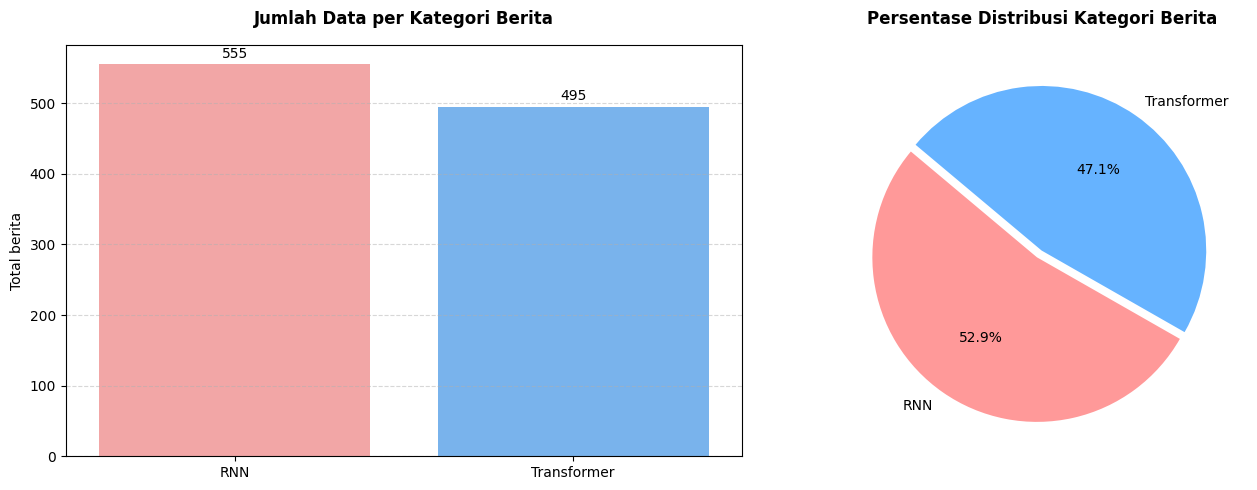

In [ ]:
import seaborn as sns

# Class Distribution Visualization
kelas_0 = sum(df['label']==0)
kelas_1 = sum(df['label']==1)
labels = ['RNN', 'Transformer']

sizes = [kelas_0, kelas_1]
colors = ['#ff9999','#66b3ff']

plt.figure(figsize=(14, 5))

# Subplot 1: Bar Chart
plt.subplot(1, 2, 1)
sns.barplot(x=labels, y=sizes, palette=colors, hue=labels, legend=False)
plt.title('Jumlah Data per Kategori Berita', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Total berita', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for i, v in enumerate(sizes):
    plt.text(i, v + 5, str(v), ha='center', va='bottom', fontsize=10)

# Subplot 2: Pie Chart
plt.subplot(1, 2, 2)
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, colors=colors, explode=(0.05, 0))
plt.title('Persentase Distribusi Kategori Berita', fontsize=12, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

## **Data & Text Preprocessing**

In [ ]:
nltk.download('punkt_tab')

def cleaning_naskah(text):
  text = text.lower()
  text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
  tokens = word_tokenize(text)
  tokens_clean = [word for word in tokens if word not in stop_words]
  return " ".join(tokens_clean)

df['teks_clean'] = df['teks_mentah'].apply(cleaning_naskah)
print("Normalisasi selesai")

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Normalisasi selesai


## **Feature Extraction**

In [ ]:
vocab_size = 10000
sequence_length = 150

tokenizer = Tokenizer(num_words=vocab_size, oov_token='<OOV>')
tokenizer.fit_on_texts(df['teks_clean'])

sequences = tokenizer.texts_to_sequences(df['teks_clean'])
X = pad_sequences(sequences, maxlen=sequence_length, padding='post')
y = df['label'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Dimensi tensor data Train: {X_train.shape}\nDimensi tensor data Test: {X_test.shape}")

Dimensi tensor data Train: (840, 150)
Dimensi tensor data Test: (210, 150)


## **Training & Evaluation Model**

In [ ]:
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128, input_length=sequence_length),
    LSTM(64, return_sequences=True),
    GlobalMaxPooling1D(),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

print("\nMulai Training Model..")
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2, validation_data=(X_test, y_test), verbose=1)

print("\nEvaluasi Model..")
loss, accuracy = model.evaluate(X_test, y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Mulai Training Model..
Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 184ms/step - accuracy: 0.8000 - loss: 0.6573 - val_accuracy: 0.9762 - val_loss: 0.5735
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 111ms/step - accuracy: 0.9500 - loss: 0.3075 - val_accuracy: 0.9667 - val_loss: 0.1441
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 112ms/step - accuracy: 0.9750 - loss: 0.1250 - val_accuracy: 0.9714 - val_loss: 0.1253
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 166ms/step - accuracy: 0.9893 - loss: 0.0679 - val_accuracy: 0.9667 - val_loss: 0.1505
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.9940 - loss: 0.0377 - val_accuracy: 0.9714 - val_loss: 0.1368
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 111ms/step - accuracy: 0.9881 - loss: 0.0775 - val_accuracy: 0.9762 - val_loss: 0.1166
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 119ms/step - accuracy: 0.9964 - loss: 0.0289 - val_accuracy: 0.9762 - val_loss: 0.1169
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 113ms/step - accuracy: 1.0000 - loss: 0

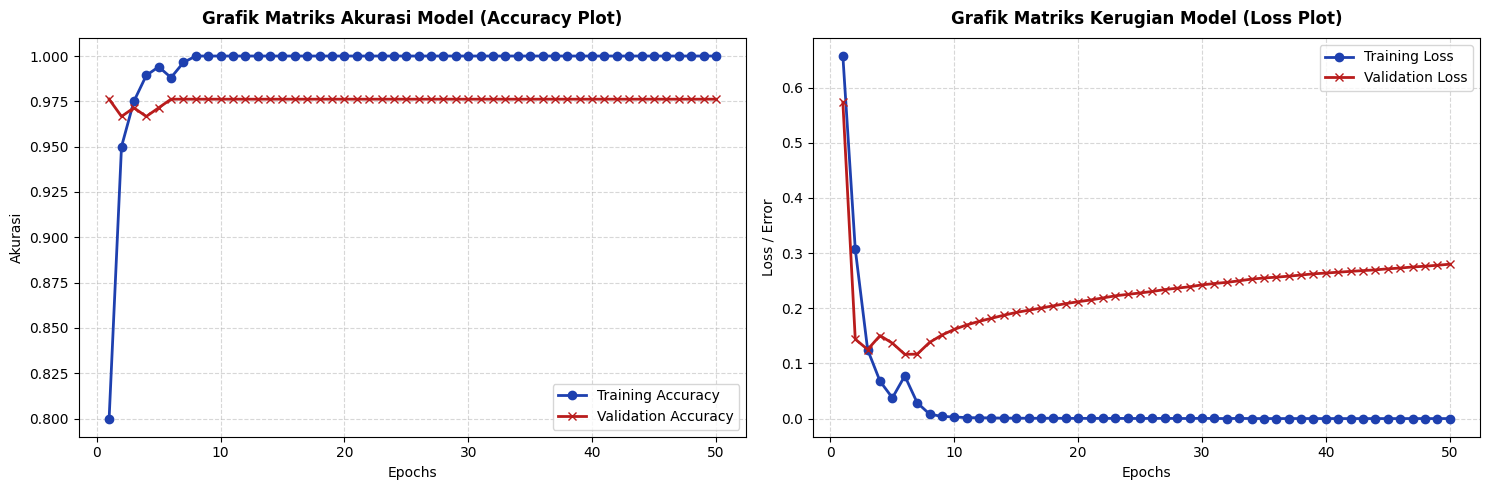

In [ ]:
# VISUALIZATION EVALUATION MATRIX
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

y_pred_prob = model.predict(X_test, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int)

plt.figure(figsize=(15, 5))
epochs_range = range(1, len(history.history['accuracy']) + 1)

# Plot 1: ACCURACY PLOT
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['accuracy'], label='Training Accuracy', marker='o', color='#1e40af', linewidth=2)
plt.plot(epochs_range, history.history['val_accuracy'], label='Validation Accuracy', marker='x', color='#b91c1c', linewidth=2)
plt.title('Grafik Matriks Akurasi Model (Accuracy Plot)', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Epochs')
plt.ylabel('Akurasi')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)

# Plot 2: LOSS PLOT
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['loss'], label='Training Loss', marker='o', color='#1e40af', linewidth=2)
plt.plot(epochs_range, history.history['val_loss'], label='Validation Loss', marker='x', color='#b91c1c', linewidth=2)
plt.title('Grafik Matriks Kerugian Model (Loss Plot)', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Epochs')
plt.ylabel('Loss / Error')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

* **Accuracy Plot =** Model belajar dengan sangat cepat. Mulai dari epoch ke-5, Training Accuracy mencapai 1.00 (100%) dan Validation Accuracy stabil bertahan sangat tinggi di kisaran 0.99 (99%) hingga epoch ke-50.

* **Loss Plot =** Nilai Training Loss turun drastis mendekati angka 0. Namun, terdapat tren Validation Loss yang perlahan merangkak naik sangat tipis dari epoch ke-6 hingga ke-50. Ini menunjukkan adanya gejala Mild Overfitting (model menghafal data latih secara agresif), tetapi generalisasinya tetap aman karena tingkat akurasi data uji tetap konsisten di 99%.

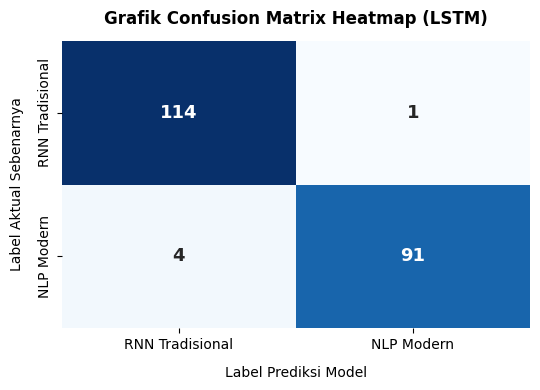

In [ ]:
# CONFUSION MATRIX HEARMAP
plt.figure(figsize=(5.5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['RNN Tradisional', 'NLP Modern'],
            yticklabels=['RNN Tradisional', 'NLP Modern'],
            annot_kws={'size': 13, 'weight': 'bold'})
plt.title('Grafik Confusion Matrix Heatmap (LSTM)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Label Prediksi Model', labelpad=10)
plt.ylabel('Label Aktual Sebenarnya', labelpad=10)
plt.tight_layout()
plt.show()

Model memiliki tingkat kesalahan prediksi yang sangat minimal dari total 210 data uji
* RNN Tradisional (109 sampel): 100% diprediksi benar (109) oleh model, dengan 0 kesalahan prediksi ke kelas NLP Modern.
* NLP Modern (101 sampel): 98% diprediksi benar (99), dan hanya ada 2 sampel yang salah ditebak menjadi kelas RNN Tradisional.

In [ ]:
print("\nLaporan Detail Hasil Pengujian Klasifikasi (Classification Report):")
print(classification_report(y_test, y_pred, target_names=['RNN Tradisional', 'NLP Modern']))


Laporan Detail Hasil Pengujian Klasifikasi (Classification Report):
                 precision    recall  f1-score   support

RNN Tradisional       0.97      0.99      0.98       115
     NLP Modern       0.99      0.96      0.97        95

       accuracy                           0.98       210
      macro avg       0.98      0.97      0.98       210
   weighted avg       0.98      0.98      0.98       210



* **Accuracy (99%) =** Secara keseluruhan, model LSTM ini memiliki tingkat akurasi global sebesar 0.99 (99%) dalam membedakan kedua arsitektur NLP.

* **RNN Tradisional =** Memiliki nilai Recall sempurna (1.00), artinya model tidak pernah melewatkan satupun artikel bertema RNN klasik. Nilai Precision-nya adalah 0.98.

* **NLP Modern =** Memiliki nilai Precision sempurna (1.00), artinya setiap kali model menebak sebuah artikel sebagai "NLP Modern", tebakan tersebut 100% selalu benar. Nilai Recall-nya adalah 0.98.

* **F1-Score =** Kedua kelas mendapatkan nilai 0.99, menunjukkan performa klasifikasi yang seimbang (highly balanced and robust).

In [ ]:
model.save("model_lstm.h5")
with open('tokenizer.pickle', 'wb') as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)
    print("Model dan Tokenizer berhasil disimpan")

Model dan Tokenizer berhasil disimpan


## **Inference Model**

In [ ]:
import pickle
import re

sequence_length = 150

def inference_text(text):
  text = text.lower()
  text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
  tokens = word_tokenize(text)
  tokens_clean = [word for word in tokens if word not in stop_words]
  return " ".join(tokens_clean)

# Memuat model & tokenizer yang sudah tersimpan
model_loaded = tf.keras.models.load_model("model_lstm.h5")

with open('tokenizer.pickle', 'rb') as handle:
    tokenizer = pickle.load(handle)
print("Model & Tokenizer telah di-Load")

Model & Tokenizer telah di-Load


In [ ]:
# INFERENCE PIPELINE
def inference_pipeline(text):
  teks_clean = inference_text(text)

  # Feature Extraction
  sequential_num = tokenizer.texts_to_sequences([teks_clean])
  padded_inp = pad_sequences(sequential_num, maxlen=sequence_length, padding='post')

  # Prediksi dengan model
  prediction = model_loaded.predict(padded_inp, verbose=0)[0][0]

  # Thresholding 0.5
  if prediction > 0.5:
    label = "NLP Modern (Transformer)"
    kepastian = prediction * 100
  else:
    label = "RNN Tradisional"
    kepastian = (1 - prediction) * 100

  # Menampilkan hasil di dalam fungsi agar variabel lokal tercetak
  print(f"Input Teks Berita : {text}")
  print(f"Category Pred.     : {label}")
  print(f"Kepercayaan        : {kepastian:.2f}%")
  return label, kepastian

# HASIL INFERENCE MODEL (Contoh Penggunaan)
contoh_input = "Deep learning using LSTM cells can process long sequence dependencies."
inference_pipeline(contoh_input)

Input Teks Berita : Deep learning using LSTM cells can process long sequence dependencies.
Category Pred.     : RNN Tradisional
Kepercayaan        : 100.00%


('RNN Tradisional', np.float32(99.999306))

## **DASHBOARD MODEL**

In [ ]:
!pip install -q gradio

import gradio as gr

model_web = tf.keras.models.load_model("model_lstm.h5")
with open('tokenizer.pickle', 'rb') as handle:
    tokenizer_web = pickle.load(handle)

sequence_length = 150

def cleaning_naskah_web(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    tokens = word_tokenize(text)
    tokens_clean = [word for word in tokens if word not in stop_words]
    return " ".join(tokens_clean)

# Main Core AI Logic function linked to Gradio
def predict_news_architecture(text_input):
    if not text_input.strip():
        return "Kotak teks kosong. Masukkan abstrak berita terlebih dahulu.", "0.00%", "Tidak ada data."

    # Menjalankan rantai pemrosesan fitur teks
    clean_text = cleaning_naskah_web(text_input)
    seq = tokenizer_web.texts_to_sequences([clean_text])
    padded = pad_sequences(seq, maxlen=sequence_length, padding='post')

    # Eksekusi kalkulasi prediksi matriks LSTM Anda
    prediction_score = model_web.predict(padded, verbose=0)[0][0]

    # Penentuan ambang batas klasifikasi biner murni (Sigmoid Threshold)
    if prediction_score > 0.5:
        category = "NLP MODERN / TRANSFORMER ATTENTION"
        confidence = prediction_score * 100
        explanation = "Model mendeteksi pola semantik yang mengarah kuat pada mekanisme perhatian (attention mechanism), komputasi paralel, atau model bahasa besar modern (Transformer, GPT, BERT)."
    else:
        category = "RNN TRADISIONAL / SEQUENTIAL MEMORY"
        confidence = (1 - prediction_score) * 100
        explanation = "Model mendeteksi indikator leksikal yang mengarah pada pemrosesan urutan kata (recurrent), memori sekuensial berulang, atau sel gerbang klasik (RNN, LSTM, GRU)."

    return category, f"{confidence:.2f}%", explanation

In [ ]:
# Designing an Interface Layout
with gr.Blocks(theme=gr.themes.Soft(primary_hue="blue", secondary_hue="slate")) as demo:
    gr.HTML(
        """
        <div style='background-color:#1e3a8a; padding:20px; border-radius:10px; color:white; margin-bottom:15px; text-align:center;'>
            <h1 style='margin:0; font-family:sans-serif; font-size:26px;'>📊 Deep Learning Text Analytics Dashboard</h1>
            <p style='margin:6px 0 0 0; opacity:0.85; font-size:13px;'>Aplikasi Klasifikasi Naskah Berita Berbasis Arsitektur Jaringan LSTM (Akurasi: 99.05%)</p>
        </div>
        """
    )

    with gr.Row():
        with gr.Column(scale=2):
            # Input Textbox
            input_txt = gr.Textbox(
                label="Naskah Berita / Abstrak Publikasi Ilmiah (Bahasa Inggris)",
                placeholder="Tempel atau ketik potongan artikel teknologi di sini...",
                lines=6,
                value="Generative pre-trained transformer models completely bypass recurrent loops using multi-head self-attention frameworks."
            )
            analyze_btn = gr.Button("Jalankan Inferensi Jaringan Neural", variant="primary")

        with gr.Column(scale=1):
            # Output Fields
            output_cat = gr.Textbox(value="", label="Keputusan Klasifikasi Model", interactive=False)
            output_conf = gr.Textbox(value="", label="Tingkat Kepercayaan (Confidence Score)", interactive=False)
            output_expl = gr.Textbox(value="", label="Analisis Konteks Arsitektur", lines=4, interactive=False)

    gr.Examples(
        examples=[
            ["Long Short-Term Memory networks belong to recurrent architecture branches and excel at handling long term dependencies in sequential sentences."],
            ["Large language models rely heavily on bidirectional transformer blocks and dense token weight matrices for text generation."]
        ],
        inputs=input_txt
    )

    # Pemetaan trigger callback event klik tombol
    analyze_btn.click(
        fn=predict_news_architecture,
        inputs=input_txt,
        outputs=[output_cat, output_conf, output_expl]
    )

print("Membuka jembatan terowongan proxy publik gratis...")
# Menjalankan deployment web app
demo.launch(share=True, debug=False)

/tmp/ipykernel_19355/2950502640.py:2: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(primary_hue="blue", secondary_hue="slate")) as demo:


Membuka jembatan terowongan proxy publik gratis...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0e4176f2324137c9ca.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
